# 04 â€” Model Training
Train the multi-sensor detector on sample/real data.

This notebook:
- Builds the full model
- Sets up training pipeline
- Trains on sample data
- Monitors loss curves

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from tqdm.auto import tqdm

from src.model import build_model, MultiSensorDetector
from src.losses import DetectionLoss
from src.dataset import MultiModalDataset
from src.utils import load_config, get_device, collate_fn, create_sample_data

%matplotlib inline
device = get_device('auto')
print(f'Device: {device}')

C:\Users\shiva\AppData\Local\Programs\Python\Python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu


In [2]:
# Create sample data if needed
DATA_DIR = os.path.join('..', 'data', 'sample')
if not os.path.exists(os.path.join(DATA_DIR, 'annotations.json')):
    create_sample_data(DATA_DIR, num_samples=50)

# Load config
cfg = load_config(os.path.join('..', 'configs', 'default.yaml'))

# Override for notebook training
cfg['model']['num_classes'] = 5
cfg['training']['epochs'] = 5  # Quick training
cfg['training']['batch_size'] = 4
cfg['dataset']['img_size'] = [320, 320]  # Smaller for speed

print('Config loaded and adjusted for notebook training')

Config loaded and adjusted for notebook training


In [3]:
# Create dataloaders
full_dataset = MultiModalDataset(
    root_dir=DATA_DIR,
    annotation_file=os.path.join(DATA_DIR, 'annotations.json'),
    img_size=(320, 320),
    augment=False
)

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_set, val_set = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_set, batch_size=4, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_set, batch_size=4, shuffle=False, collate_fn=collate_fn)

print(f'Train: {len(train_set)} | Val: {len(val_set)}')

Train: 8 | Val: 2


In [4]:
# Build model
model = build_model(cfg).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters: {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')

# Loss and optimizer
criterion = DetectionLoss(num_classes=5)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=5)

Total parameters: 53,158,966
Trainable parameters: 50,463,158


In [5]:
# Training loop
num_epochs = 5
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    # Train
    model.train()
    epoch_loss = 0
    num_batches = 0
    
    for batch in tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}'):
        rgb = batch['rgb'].to(device)
        thermal = batch['thermal'].to(device)
        targets = [{k: v.to(device) for k, v in t.items()} for t in batch['targets']]
        
        predictions = model(rgb, thermal)
        loss_dict = criterion(predictions, targets)
        loss = loss_dict['total_loss']
        
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        optimizer.step()
        
        epoch_loss += loss.item()
        num_batches += 1
    
    avg_train_loss = epoch_loss / max(num_batches, 1)
    train_losses.append(avg_train_loss)
    
    # Validate
    model.eval()
    val_loss = 0
    val_batches = 0
    with torch.no_grad():
        for batch in val_loader:
            rgb = batch['rgb'].to(device)
            thermal = batch['thermal'].to(device)
            targets = [{k: v.to(device) for k, v in t.items()} for t in batch['targets']]
            
            predictions = model(rgb, thermal)
            loss_dict = criterion(predictions, targets)
            val_loss += loss_dict['total_loss'].item()
            val_batches += 1
    
    avg_val_loss = val_loss / max(val_batches, 1)
    val_losses.append(avg_val_loss)
    
    scheduler.step()
    
    print(f'Epoch {epoch+1}: Train Loss={avg_train_loss:.4f}, Val Loss={avg_val_loss:.4f}')

Epoch 1/5:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch 1/5:  50%|█████     | 1/2 [00:37<00:37, 37.96s/it]

Epoch 1/5: 100%|██████████| 2/2 [01:10<00:00, 34.93s/it]

Epoch 1/5: 100%|██████████| 2/2 [01:10<00:00, 35.40s/it]

Epoch 1: Train Loss=11.4922, Val Loss=3.6811


...

Epoch 5/5:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch 5/5:  50%|█████     | 1/2 [00:31<00:31, 31.83s/it]

Epoch 5/5: 100%|██████████| 2/2 [01:06<00:00, 33.28s/it]

Epoch 5/5: 100%|██████████| 2/2 [01:06<00:00, 33.09s/it]

Epoch 5: Train Loss=7.8172, Val Loss=3.3197


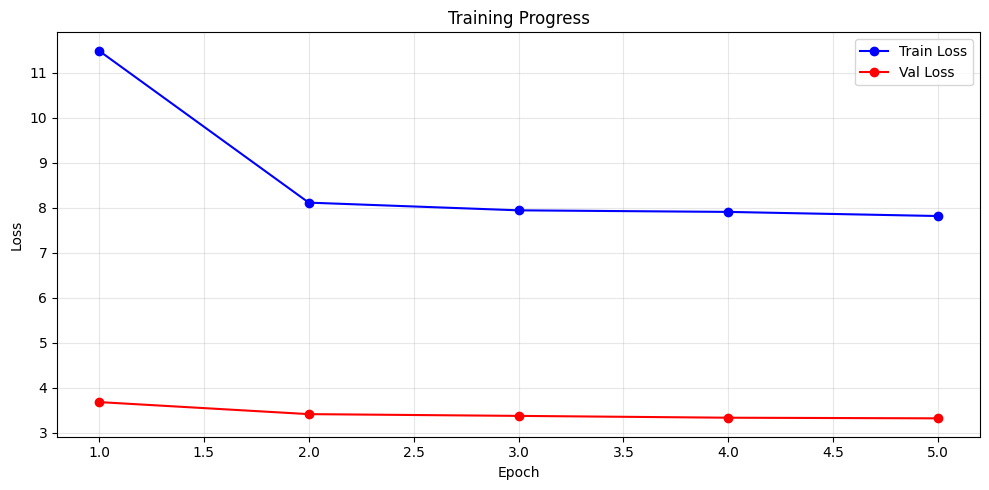

In [6]:
# Plot training curves
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, len(train_losses)+1), train_losses, 'b-o', label='Train Loss')
ax.plot(range(1, len(val_losses)+1), val_losses, 'r-o', label='Val Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Training Progress')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# Save model
save_dir = os.path.join('..', 'weights')
os.makedirs(save_dir, exist_ok=True)
torch.save({
    'model_state_dict': model.state_dict(),
    'config': cfg
}, os.path.join(save_dir, 'notebook_trained.pth'))
print('Model saved!')

Model saved!
